Original Dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Shape:
(1005, 8)

Duplicate Rows:
0       False
1       False
2       False
3       False
4       False
        ...  
1000     True
1001    

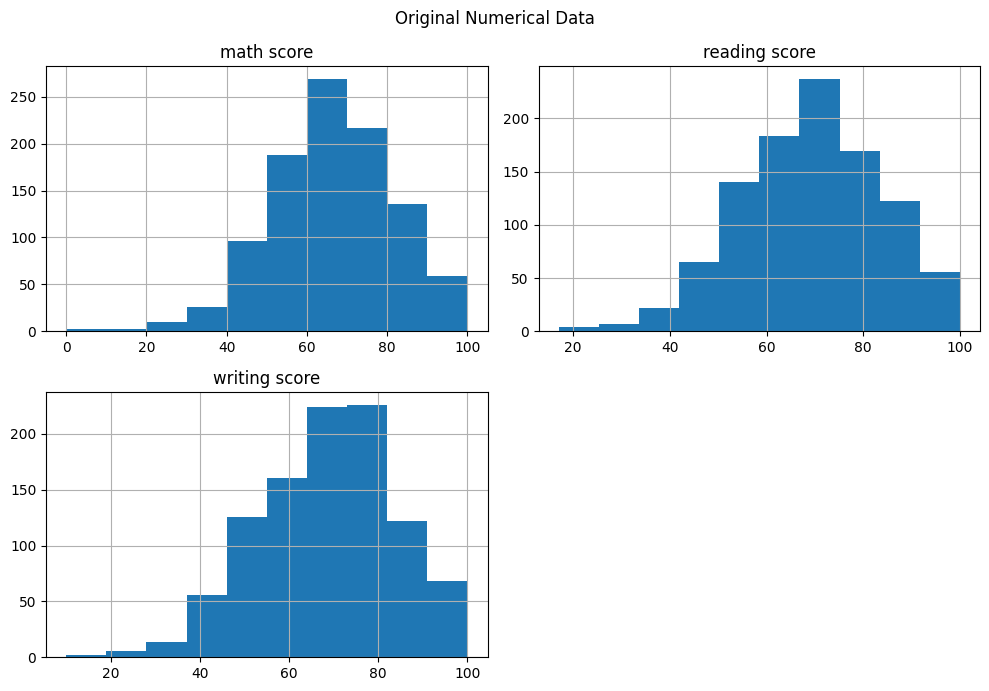

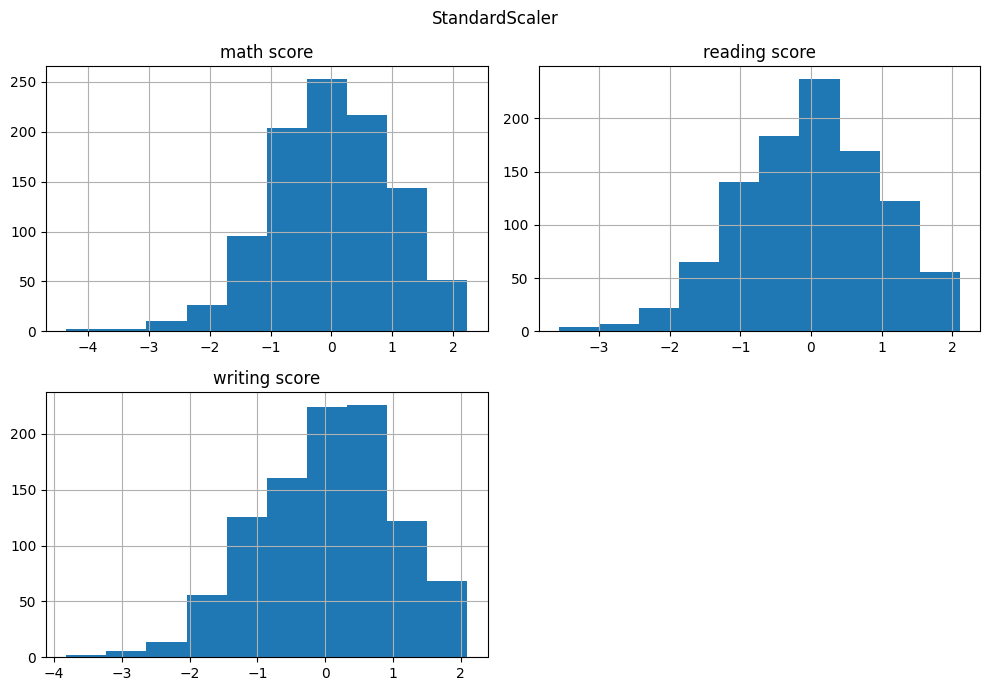

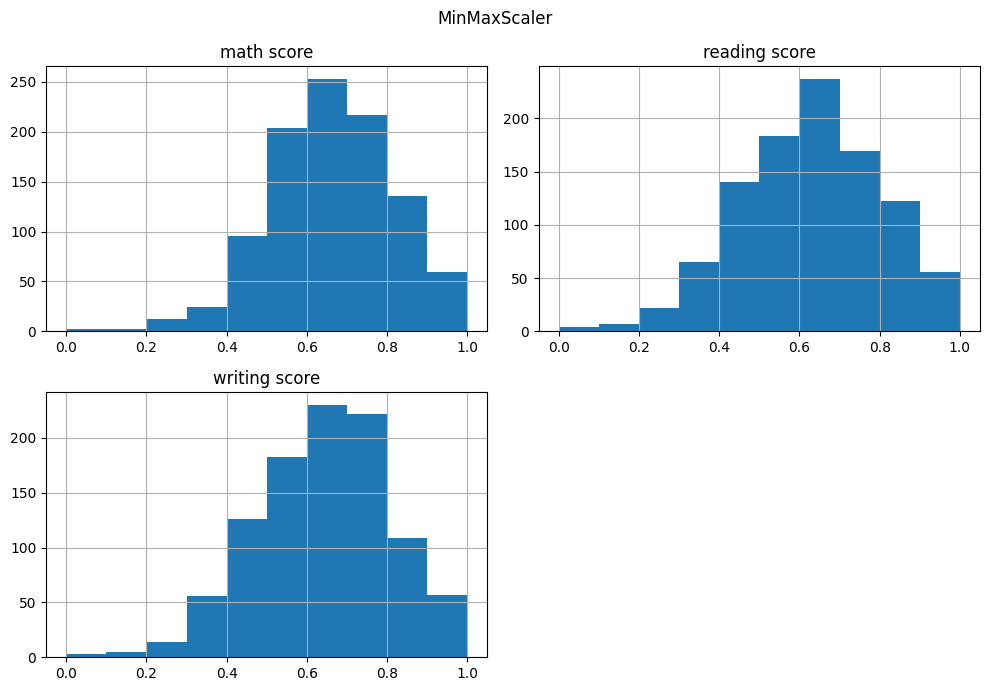

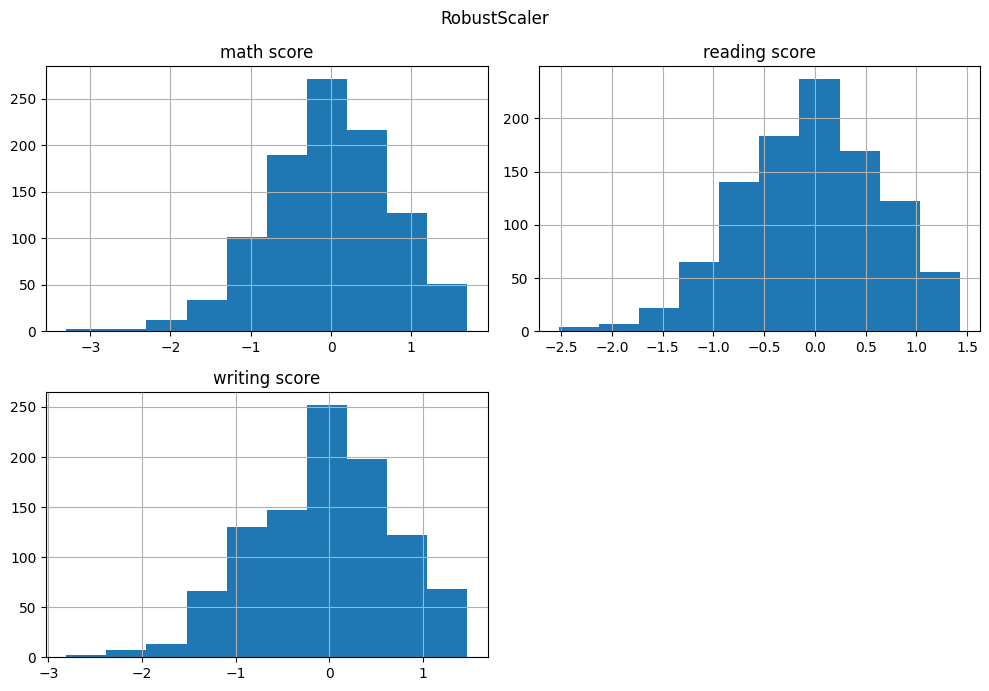

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler

df = pd.read_csv("StudentsPerformance.csv")

print("Original Dataset:")
print(df.head())

print("\nShape:")
print(df.shape)

print("\nDuplicate Rows:")
print(df.duplicated())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].mean())

print("\nDataset After fillna():")
print(df.head())

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nNumerical Columns:")
print(list(numerical_columns))

numerical_data = df[numerical_columns]

print("\nOriginal Numerical Data:")
print(numerical_data.head())

standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(numerical_data)

standard_df = pd.DataFrame(
    standard_scaled,
    columns=numerical_columns
)

print("\nStandardScaler Data:")
print(standard_df.head())

minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(numerical_data)

minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=numerical_columns
)

print("\nMinMaxScaler Data:")
print(minmax_df.head())

robust_scaler = RobustScaler()
robust_scaled = robust_scaler.fit_transform(numerical_data)

robust_df = pd.DataFrame(
    robust_scaled,
    columns=numerical_columns
)

print("\nRobustScaler Data:")
print(robust_df.head())

print("\nStandardScaler Mean:")
print(standard_df.mean())

print("\nStandardScaler Standard Deviation:")
print(standard_df.std())

print("\nMinMaxScaler Minimum:")
print(minmax_df.min())

print("\nMinMaxScaler Maximum:")
print(minmax_df.max())

print("\nRobustScaler Median:")
print(robust_df.median())

numerical_data.hist(figsize=(10, 7), bins=10)
plt.suptitle("Original Numerical Data")
plt.tight_layout()
plt.show()

standard_df.hist(figsize=(10, 7), bins=10)
plt.suptitle("StandardScaler")
plt.tight_layout()
plt.show()

minmax_df.hist(figsize=(10, 7), bins=10)
plt.suptitle("MinMaxScaler")
plt.tight_layout()
plt.show()

robust_df.hist(figsize=(10, 7), bins=10)
plt.suptitle("RobustScaler")
plt.tight_layout()
plt.show()